# LightGBM + AutoETS: feature pruning, log target and blending

**Question.** Starting from `lightgbm_baseline.ipynb`: does LightGBM get better on the leaderboard metrics, **MAPE** for the point forecast and the **Winkler score** for the 95% interval, if we (1) drop the weak weather groups, (2) train on `log(y)`, and (3) blend it with AutoETS the way `forecast.ipynb` blends its models?

**Protocol.** Every choice (features, target scale, blend weight per forecast day, interval widths) is made on **14 cross-validation windows** with one rule (Section 3). The **14-day holdout** (7 windows) is scored once at the end with everything frozen. The previous notebook used 7 CV windows; with 4 decisions to make, 7 windows proved too noisy (Section 4 shows a ranking that flips).

**Short answer** (numbers from the run below):
- **Feature pruning does not help.** Every removal scores worse on CV; the full feature set stays (Section 4).
- **The log target does.** LightGBM on `log(y)` cuts CV MAPE from 57.6% to 49.9% for a small RMSE cost (Section 4).
- **Blending:** AutoETS never helps. Seasonal naive helps a little on day 2 only, so the submitted model is LightGBM alone on day 1 and **0.75 · LightGBM + 0.25 · seasonal naive on day 2**. The CV gain over LightGBM alone is small (Winkler 1094 vs 1113, MAPE 49.6% vs 49.9%) (Section 5).
- **Holdout:** the submitted model has MAPE 351% vs 577% for seasonal naive and 611% for the previous submission, and Winkler 1030 vs 1464 and 2447 (Section 6). LightGBM alone did better on the holdout (326%, 959): the day-2 blend did not carry over, which is a reminder that its CV gain was within noise.
- **Intervals must follow the level.** Fixed widths calibrated at a level of about 820 are far too wide at the forecast origin (about 360). The submitted interval is level-scaled, a choice made on the holdout because CV cannot test it (Section 6.1).
- **The previous submission's interval is too narrow on the holdout:** it covers only 53% of CV hours and 58% of holdout hours, which is where most of its Winkler penalty comes from.
- **MAPE is fragile:** about three quarters of every model's holdout MAPE comes from 34 near-zero night hours (`y < 20`).

Helpers live in `src/final/lgbm_baseline.py`. The caveat from the baseline notebook still applies: historical scores use *observed* weather, so LightGBM's numbers are optimistic.

In [1]:
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='IProgress not found')
warnings.filterwarnings('ignore', category=FutureWarning)

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from final.lgbm_baseline import (
    DAY, DAY_PARTS, H, MODEL_COLORS, MODEL_NAMES, PARTS,
    autoets, calibrate_halfwidths, interval, make_features, mape, recent_level,
    plot_window_grid, rmse, seasonal_naive, winkler,
)

plt.rcParams.update({
    'figure.figsize': (11, 4),
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
pd.set_option('display.precision', 2)

ROOT = Path.cwd() if (Path.cwd() / 'data/train.csv').exists() else Path.cwd().parent
TRAIN_WINDOW_DAYS = 180
ETS_TRAIN_DAYS = 46
CV_N_FOLDS = 14
HOLDOUT_DAYS = 14
BLEND_WEIGHTS = [0, 0.25, 0.5, 0.75, 1]
INTERVAL_LEVEL_DAYS = 7     # Level-scaled intervals: errors relative to the mean of the last 7 days.
SUBMISSION_SCALE = 0.7      # Interval scale used by the saved forecast in forecast.ipynb.
SEED = 42

LGBM_PARAMS = dict(
    objective='regression', n_estimators=180, learning_rate=0.05, num_leaves=15,
    min_child_samples=40, reg_lambda=2.0, random_state=SEED, n_jobs=4, verbosity=-1,
)

MODEL_NAMES.update({'previous': 'Previous submission (forecast.ipynb)'})
MODEL_COLORS.update({'previous': '#8c564b'})  # Brown, so it is not confused with the grey history line.

In [2]:
data = pd.read_csv(ROOT / 'data/train.csv', parse_dates=['ds']).sort_values('ds').reset_index(drop=True)
future_weather = pd.read_csv(ROOT / 'data/weather_forecast.csv', parse_dates=['ds']).sort_values('ds').reset_index(drop=True)
y = data['y'].to_numpy(dtype=float)
daylight = data['daylight'].to_numpy(dtype=int)
N = len(y)

holdout_start = N - HOLDOUT_DAYS * DAY
holdout_origins = np.arange(holdout_start, N - H + 1, H, dtype=int)
cv_origins = holdout_start - H - np.arange(CV_N_FOLDS - 1, -1, -1) * H
all_origins = [*cv_origins, *holdout_origins]
first_training_origin = int(cv_origins[0]) - TRAIN_WINDOW_DAYS * DAY

frames = []
for origin in range(first_training_origin, N - H + 1, DAY):
    frame = make_features(y, origin, data.iloc[origin : origin + H])
    frame['origin'] = origin
    frame['target'] = y[origin : origin + H]
    frames.append(frame)
supervised = pd.concat(frames, ignore_index=True)
all_features = [c for c in supervised.columns if c not in ('origin', 'target')]

print(f'CV: {CV_N_FOLDS} windows from {data.ds.iloc[cv_origins[0]]:%Y-%m-%d} to {data.ds.iloc[cv_origins[-1] + H - 1]:%Y-%m-%d}')
print(f'Holdout: {len(holdout_origins)} windows from {data.ds.iloc[holdout_start]:%Y-%m-%d} to {data.ds.iloc[-1]:%Y-%m-%d}')

CV: 14 windows from 2026-09-15 to 2026-10-13
Holdout: 7 windows from 2026-10-13 to 2026-10-27


## 1. Why MAPE needs care here

MAPE divides every error by the actual value. On calm nights generation drops almost to zero (the minimum is 0.7), so a forecast of 50 on such an hour costs 7000% while the same error at noon costs 3%. The left chart shows how far the quiet tail drops at night; the right one shows that the holdout contains a few hours far below everything else. Section 6 measures how much of each model's MAPE they cause.

Two consequences:
- MAPE rewards **forecasting low at night**. A model trained on `log(y)` minimises relative errors, so it should help (Section 4).
- MAPE averages are **dominated by a handful of hours**. A model that beats naive on RMSE can still lose on MAPE, and the hidden 48 hours may or may not contain such a calm night.

Holdout hours with y < 20: 34 of 336


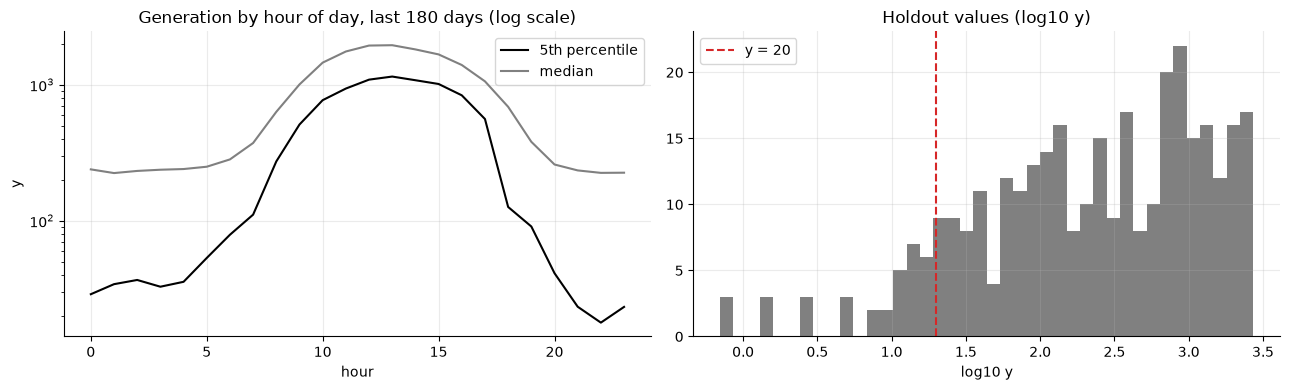

In [3]:
hours = pd.DataFrame({'ds': data.ds, 'y': y, 'hour': data.ds.dt.hour})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
recent = hours.iloc[-TRAIN_WINDOW_DAYS * DAY:]
recent.groupby('hour').y.quantile(0.05).plot(ax=axes[0], color='black', label='5th percentile')
recent.groupby('hour').y.median().plot(ax=axes[0], color='grey', label='median')
axes[0].set(yscale='log', title='Generation by hour of day, last 180 days (log scale)', ylabel='y')
axes[0].legend()

holdout_y = y[holdout_start:]
print(f'Holdout hours with y < 20: {np.sum(holdout_y < 20)} of {len(holdout_y)}')
axes[1].hist(np.log10(holdout_y), bins=40, color='grey')
axes[1].axvline(np.log10(20), color='tab:red', ls='--', label='y = 20')
axes[1].set(title='Holdout values (log10 y)', xlabel='log10 y')
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Models and helpers

- `lgbm(origin, columns, log)` refits LightGBM on the 180 days before the origin, optionally on `log(y)` (forecasts are `exp` of the prediction).
- `previous_submission(origin)` reproduces the forecast saved by `forecast.ipynb`: the mean of AutoETS, seasonal naive and the 3-day same-hour mean, with the seasonal-naive interval scaled by 0.7.
- `pooled(...)` scores a set of windows by concatenating their hours. Skill is RMSE / seasonal-naive RMSE over the same hours.

In [4]:
lgbm_cache = {}
ets = {o: autoets(data, o, ETS_TRAIN_DAYS) for o in all_origins}
naive = {o: seasonal_naive(y, o) for o in all_origins}


def lgbm(origin, columns=tuple(all_features), log=True):
    key = (int(origin), tuple(columns), log)
    if key not in lgbm_cache:
        train = supervised[supervised.origin.between(origin - TRAIN_WINDOW_DAYS * DAY, origin - H)]
        target = np.log(train.target) if log else train.target
        model = lgb.LGBMRegressor(**LGBM_PARAMS).fit(train[list(columns)], target)
        X = make_features(y, origin, data.iloc[origin : origin + H])[list(columns)]
        pred = model.predict(X)
        lgbm_cache[key] = np.exp(pred) if log else np.maximum(pred, 0.1)
    return lgbm_cache[key]


def previous_submission(origin):
    past = y[:origin]
    sigma = np.std(past[DAY:] - past[:-DAY], ddof=1)
    half = 1.96 * sigma * np.sqrt(np.arange(H) // DAY + 1)
    three_day = np.tile(past[-3 * DAY:].reshape(3, DAY).mean(axis=0), H // DAY)
    point = (ets[origin] + naive[origin] + three_day) / 3
    lower = np.minimum(np.clip(naive[origin] - half, 0, None), point)
    upper = np.maximum(naive[origin] + half, point)
    return point, np.clip(point - SUBMISSION_SCALE * (point - lower), 0, None), point + SUBMISSION_SCALE * (upper - point)


def pooled(origins, point, bands=None, parts=PARTS):
    """Scores over the concatenated hours of the given windows, per forecast-day part."""
    rows = {}
    for part, sl in parts.items():
        actual = np.concatenate([y[o : o + H][sl] for o in origins])
        pred = np.concatenate([point[o][sl] for o in origins])
        base = np.concatenate([naive[o][sl] for o in origins])
        row = {'skill': rmse(actual, pred) / rmse(actual, base), 'RMSE': rmse(actual, pred), 'MAPE %': mape(actual, pred)}
        if bands is not None:
            lower = np.concatenate([bands[o][0][sl] for o in origins])
            upper = np.concatenate([bands[o][1][sl] for o in origins])
            row |= {'coverage': np.mean((actual >= lower) & (actual <= upper)),
                    'width': np.mean(upper - lower), 'Winkler': winkler(actual, lower, upper)}
        rows[part] = row
    return pd.DataFrame(rows).T


def calibrated_bands(point, calibration_origins=cv_origins, level_days=None):
    widths = calibrate_halfwidths(y, daylight, calibration_origins, point, level_days=level_days)
    scale = (lambda o: recent_level(y, o, level_days)) if level_days else (lambda o: 1.0)
    return {o: interval(point[o], daylight[o : o + H], widths, scale(o)) for o in point}

## 3. Selection rule

Each decision below is made with one score on the CV windows: **MAPE and Winkler, each divided by the seasonal-naive value, then added**. Both leaderboard metrics count equally, and 2.0 means "as good as naive". Winkler is computed with day/night intervals calibrated on the candidate's own CV errors, so every candidate gets a fair interval.

In [5]:
def cv_report(point, parts=PARTS):
    return pooled(cv_origins, point, calibrated_bands(point), parts=parts)


naive_cv = cv_report(naive)


def selection_score(table, part='1–48'):
    return (table.loc[part, 'MAPE %'] / naive_cv.loc[part, 'MAPE %']
            + table.loc[part, 'Winkler'] / naive_cv.loc[part, 'Winkler'])

## 4. Feature pruning and the log target

The ablation in the baseline notebook found that only *Sun and clouds* had an effect clearly above noise. Here each weaker group is removed in turn, with the raw and the log target. Lower is better everywhere; the dashed line marks the full feature set on `log(y)`.

Chosen: drop 'nothing (all features)', target log(y) (19 features)


score       MAPE %         Winkler           \
target                          log(y)     y log(y)      y   log(y)        y   
dropped                                                                        
nothing (all features)            1.56  1.64  49.90  57.59  1112.51  1069.95   
Wind                              1.67  1.82  57.40  67.40  1114.58  1124.05   
Other weather                     1.64  1.69  52.23  59.24  1170.82  1103.31   
Wind + Other weather              1.73  1.89  59.33  71.41  1153.54  1141.11   
Wind + Other + day_of_week/year   1.57  1.64  47.39  55.09  1167.25  1109.87   

                                 skill        
target                          log(y)     y  
dropped                                       
nothing (all features)            0.82  0.78  
Wind                              0.85  0.82  
Other weather                     0.88  0.81  
Wind + Other weather              0.88  0.87  
Wind + Other + day_of_week/year   0.91  0.84

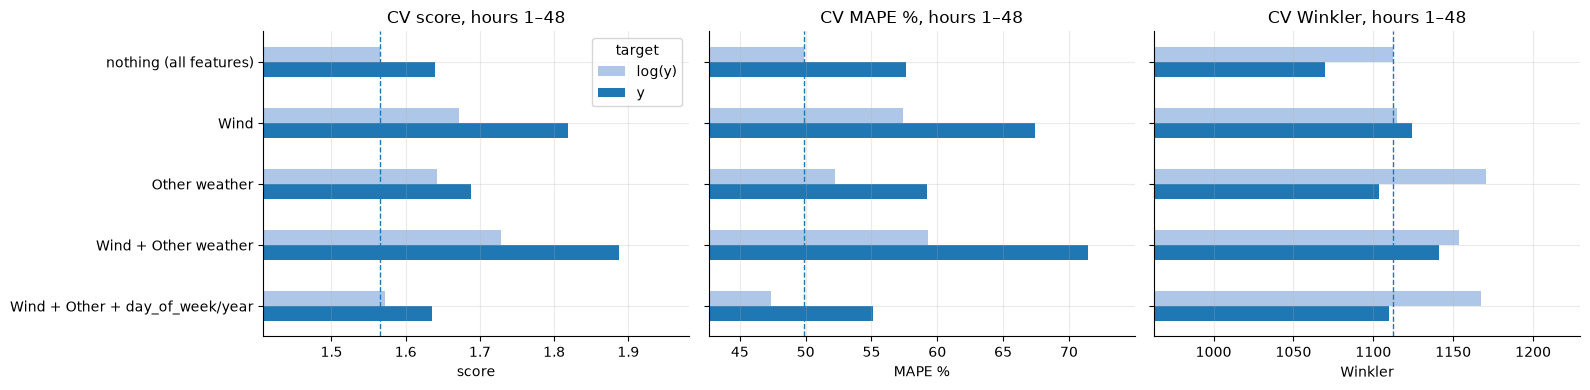

In [6]:
drop_groups = {
    'nothing (all features)': [],
    'Wind': ['wind_speed', 'air_density'],
    'Other weather': ['temperature', 'pressure', 'humidity'],
    'Wind + Other weather': ['wind_speed', 'air_density', 'temperature', 'pressure', 'humidity'],
    'Wind + Other + day_of_week/year': ['wind_speed', 'air_density', 'temperature', 'pressure', 'humidity',
                                        'day_of_week', 'day_of_year'],
}
rows = []
for dropped, cols_out in drop_groups.items():
    columns = tuple(c for c in all_features if c not in cols_out)
    for log in (False, True):
        table = cv_report({o: lgbm(o, columns, log) for o in cv_origins})
        rows.append({'dropped': dropped, 'target': 'log(y)' if log else 'y', 'columns': columns, 'log': log,
                     **table.loc['1–48', ['skill', 'MAPE %', 'Winkler']], 'score': selection_score(table)})
pruning = pd.DataFrame(rows)
best = pruning.loc[pruning.score.idxmin()]
FEATURES, LOG_TARGET = list(best.columns), bool(best.log)
print(f'Chosen: drop {best.dropped!r}, target {best.target} ({len(FEATURES)} features)')
display(pruning.pivot(index='dropped', columns='target', values=['score', 'MAPE %', 'Winkler', 'skill'])
        .reindex(drop_groups).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, metric in zip(axes, ['score', 'MAPE %', 'Winkler']):
    table = pruning.pivot(index='dropped', columns='target', values=metric).reindex(drop_groups)
    table.plot.barh(ax=ax, color=['#aec7e8', '#1f77b4'], legend=ax is axes[0])
    ax.axvline(table.iloc[0]['log(y)'], color='#1f77b4', ls='--', lw=1)
    ax.set(title=f'CV {metric}, hours 1–48', xlabel=metric, ylabel='')
    ax.set_xlim(left=table.min().min() * 0.9)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

**Reading.** Removing a weather group always makes the score worse, even though each group looked weak in the ablation: the groups carry overlapping information, and removing several at once hurts most. Dropping Wind, Other weather *and* the calendar columns nearly ties the full set (score 1.57 vs 1.56): lower MAPE, higher Winkler. With a tie the full set stays. On 7 windows (the baseline notebook) dropping Wind looked harmless; on 14 windows it is clearly worse.

The log target trades RMSE (skill) for MAPE: it predicts lower on quiet hours, which is what MAPE rewards.

## 5. Blending with AutoETS or seasonal naive

The blend is `w · LightGBM + (1 − w) · partner`, where the partner is AutoETS (as in `forecast.ipynb`) or seasonal naive, with the LightGBM model chosen above. Partner and weight are chosen separately for forecast day 1 and day 2. A blend helps only when the models make *different* errors, so first the correlation of their CV errors:

,1–24,25–48,1–48
"corr(LightGBM error, AutoETS error)",0.63,0.71,0.67
"corr(LightGBM error, Seasonal naive error)",0.74,0.76,0.74


Submitted: LightGBM, day 2 mixed with 25% Seasonal naive


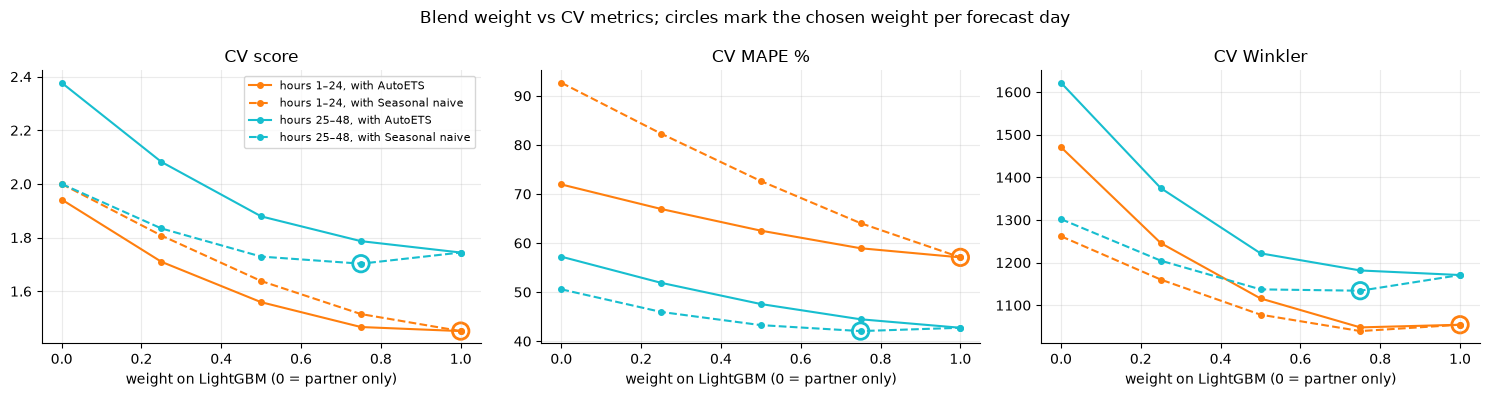

In [7]:
lgbm_best = {o: lgbm(o, FEATURES, LOG_TARGET) for o in all_origins}
partners = {'autoets': ets, 'naive': naive}


def cv_errors(point, sl):
    return np.concatenate([(y[o : o + H] - point[o])[sl] for o in cv_origins])


errors = pd.DataFrame({
    part: [np.corrcoef(cv_errors(lgbm_best, sl), cv_errors(partners[k], sl))[0, 1] for k in partners]
    for part, sl in PARTS.items()
}, index=[f'corr(LightGBM error, {MODEL_NAMES[k]} error)' for k in partners])
display(errors.round(2))


def blend(day1, day2):
    # day1, day2: (partner key, weight on LightGBM)
    weights = np.repeat([day1[1], day2[1]], DAY)
    partner = {o: np.concatenate([partners[day1[0]][o][:DAY], partners[day2[0]][o][DAY:]]) for o in all_origins}
    return {o: weights * lgbm_best[o] + (1 - weights) * partner[o] for o in all_origins}


curve = []
for key in partners:
    for w in BLEND_WEIGHTS:
        table = cv_report(blend((key, w), (key, w)))
        curve += [{'partner': key, 'w': w, 'part': part, **table.loc[part], 'score': selection_score(table, part)}
                  for part in DAY_PARTS]
curve = pd.DataFrame(curve)
chosen = curve.loc[curve.groupby('part')['score'].idxmin()].set_index('part')
chosen_blend = {part: (chosen.loc[part, 'partner'], chosen.loc[part, 'w']) for part in DAY_PARTS}
# Label for plots and tables, e.g. 'Submitted: LightGBM, day 2 mixed with 25% Seasonal naive'.
SUBMITTED_NAME = 'Submitted: LightGBM' + ''.join(
    f', day {day} mixed with {1 - w:.0%} {MODEL_NAMES[key]}'
    for day, (key, w) in enumerate(chosen_blend.values(), start=1) if w < 1
)
print(SUBMITTED_NAME)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, metric in zip(axes, ['score', 'MAPE %', 'Winkler']):
    for part, color in zip(DAY_PARTS, ['#ff7f0e', '#17becf']):
        for key, style in zip(partners, ['-', '--']):
            sub = curve[(curve.part == part) & (curve.partner == key)].set_index('w')
            ax.plot(sub.index, sub[metric], 'o' + style, color=color, ms=4,
                    label=f'hours {part}, with {MODEL_NAMES[key]}')
        key, w = chosen_blend[part]
        point = curve[(curve.part == part) & (curve.partner == key) & (curve.w == w)][metric].iloc[0]
        ax.scatter(w, point, s=140, facecolors='none', edgecolors=color, lw=2)
    ax.set(title=f'CV {metric}', xlabel='weight on LightGBM (0 = partner only)')
axes[0].legend(fontsize=8)
fig.suptitle('Blend weight vs CV metrics; circles mark the chosen weight per forecast day')
plt.tight_layout()
plt.show()

**Reading.** Seasonal naive's errors are even more correlated with LightGBM's than AutoETS's are (about 0.75 vs 0.65–0.7). AutoETS is weaker on both days, so every step towards it raises MAPE and Winkler. Seasonal naive is weaker too, but on day 2 a quarter of it lowers both MAPE (42.1% vs 42.7%) and Winkler (1134 vs 1171) a little. On day 1 the same mix lowers Winkler slightly but raises MAPE more, so LightGBM alone wins. The day-2 gain is small, so LightGBM alone and the two 50/50 blends stay in the holdout table for comparison.

## 6. Final holdout

All settings are frozen: features, target, blend weights and interval widths from the 14 CV windows. Every model gets day/night intervals from its own CV errors, except the previous submission, which keeps its own interval rule (the seasonal-naive interval scaled by 0.7).

The last column is the share of each model's holdout MAPE that comes from the 34 hours with `y < 20`.

In [8]:
submitted = blend(chosen_blend['1–24'], chosen_blend['25–48'])
candidates = {'submitted': submitted, 'lgbm': lgbm_best, 'ets50': blend(('autoets', 0.5), ('autoets', 0.5)),
              'naive50': blend(('naive', 0.5), ('naive', 0.5)), 'autoets': ets, 'naive': naive}
bands = {name: calibrated_bands(point) for name, point in candidates.items()}
previous = {o: previous_submission(o) for o in all_origins}
candidates['previous'] = {o: previous[o][0] for o in all_origins}
bands['previous'] = {o: previous[o][1:] for o in all_origins}

MODEL_NAMES.update({'submitted': SUBMITTED_NAME, 'lgbm': 'LightGBM log(y) alone',
                    'ets50': '50/50 LightGBM + AutoETS', 'naive50': '50/50 LightGBM + naive'})
MODEL_COLORS.update({'submitted': '#d62728', 'lgbm': '#1f77b4', 'ets50': '#c5b0d5', 'naive50': '#98df8a'})
holdout_actual = np.concatenate([y[o : o + H] for o in holdout_origins])
quiet = holdout_actual < 20


def quiet_share(point):
    ape = np.abs(holdout_actual - np.concatenate([point[o] for o in holdout_origins])) / holdout_actual
    return ape[quiet].sum() / ape.sum()


results = pd.concat({
    stage: pd.concat({MODEL_NAMES[k]: pooled(origins, candidates[k], bands[k]).loc['1–48'] for k in candidates}, axis=1).T
    for stage, origins in [('CV (14 windows)', cv_origins), ('Holdout (7 windows)', holdout_origins)]
}, axis=1)
results = results[[(s, m) for s in ('CV (14 windows)', 'Holdout (7 windows)')
                   for m in ('MAPE %', 'Winkler', 'coverage', 'skill')]]
results[('Holdout (7 windows)', 'MAPE share from y < 20')] = [quiet_share(candidates[k]) for k in candidates]
display(results.round(2))

CV (14 windows)           \
                                                            MAPE %  Winkler   
Submitted: LightGBM, day 2 mixed with 25% Seaso...           49.56  1094.12   
LightGBM log(y) alone                                        49.90  1112.51   
50/50 LightGBM + AutoETS                                     55.04  1168.78   
50/50 LightGBM + naive                                       57.94  1107.50   
AutoETS                                                      64.57  1546.11   
Seasonal naive                                               71.61  1281.78   
Previous submission (forecast.ipynb)                         66.11  3901.91   

                                                                   \
                                                   coverage skill   
Submitted: LightGBM, day 2 mixed with 25% Seaso...     0.95  0.81   
LightGBM log(y) alone                                  0.95  0.82   
50/50 LightGBM + AutoETS                               0.95  0.87   
50/50 LightGBM + naive                                 0.95  0.85   
AutoETS                                                0.95  1.10   
Seasonal naive                                         0.95  1.00   
Previous submission (forecast.ipynb)                   0.53  0.94   

                                                   Holdout (7 windows)  \
                                                                MAPE %   
Submitted: LightGBM, day 2 mixed with 25% Seaso...              350.85   
LightGBM log(y) alone                                           326.38   
50/50 LightGBM + AutoETS                                        333.54   
50/50 LightGBM + naive                                          444.98   
AutoETS                                                         352.09   
Seasonal naive                                                  577.04   
Previous submission (forecast.ipynb)                            610.68   

                                                                            \
                                                    Winkler coverage skill   
Submitted: LightGBM, day 2 mixed with 25% Seaso...  1030.04     0.95  0.89   
LightGBM log(y) alone                                959.27     0.96  0.89   
50/50 LightGBM + AutoETS                            1193.02     0.93  0.97   
50/50 LightGBM + naive                              1090.05     0.96  0.85   
AutoETS                                             2221.82     0.88  1.65   
Seasonal naive                                      1463.81     0.95  1.00   
Previous submission (forecast.ipynb)                2447.21     0.58  0.91   

                                                                           
                                                   MAPE share from y < 20  
Submitted: LightGBM, day 2 mixed with 25% Seaso...                   0.76  
LightGBM log(y) alone                                                0.74  
50/50 LightGBM + AutoETS                                             0.76  
50/50 LightGBM + naive                                               0.82  
AutoETS                                                              0.76  
Seasonal naive                                                       0.85  
Previous submission (forecast.ipynb)                                 0.85

MAPE %          Winkler  \
                                                      1–24   25–48     1–24   
Submitted: LightGBM, day 2 mixed with 25% Seaso...  432.63  269.08  1003.66   
LightGBM log(y) alone                               432.63  220.13  1003.66   
50/50 LightGBM + AutoETS                            418.53  248.55  1047.98   
50/50 LightGBM + naive                              568.10  321.85   856.69   
AutoETS                                             413.62  290.56  1666.70   
Seasonal naive                                      716.29  437.78   998.55   
Previous submission (forecast.ipynb)                875.61  345.75  1683.64   

                                                            coverage        
                                                      25–48     1–24 25–48  
Submitted: LightGBM, day 2 mixed with 25% Seaso...  1056.43     0.94  0.96  
LightGBM log(y) alone                                914.89     0.94  0.98  
50/50 LightGBM + AutoETS                            1338.05     0.92  0.93  
50/50 LightGBM + naive                              1323.41     0.98  0.93  
AutoETS                                             2776.94     0.92  0.84  
Seasonal naive                                      1929.07     0.99  0.92  
Previous submission (forecast.ipynb)                3210.79     0.61  0.55

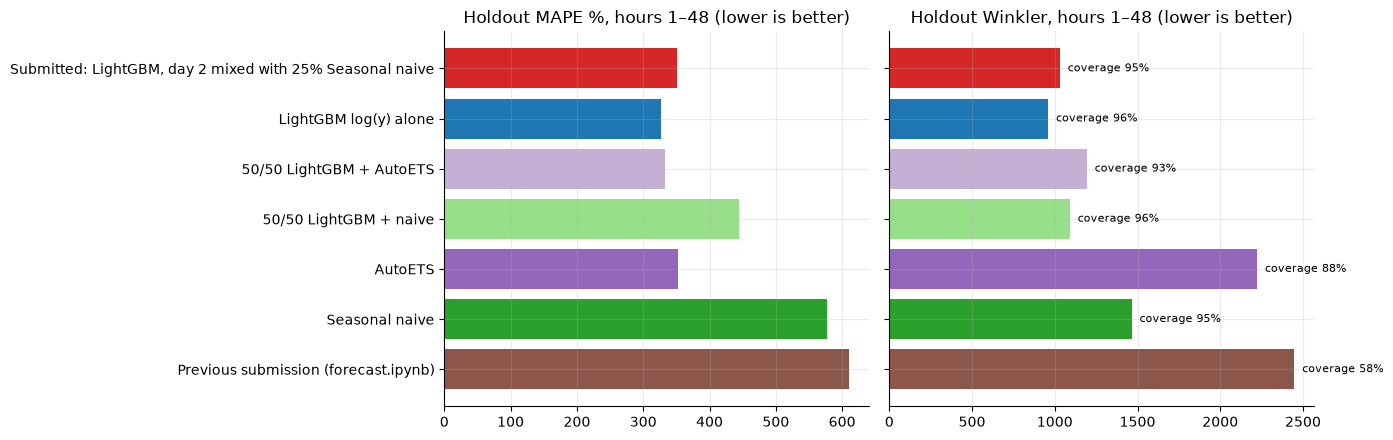

In [9]:
keys = list(candidates)
by_day = pd.concat({MODEL_NAMES[k]: pooled(holdout_origins, candidates[k], bands[k]).loc[DAY_PARTS, ['MAPE %', 'Winkler', 'coverage']]
                    for k in keys})
display(by_day.unstack().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
holdout_table = results['Holdout (7 windows)'].loc[[MODEL_NAMES[k] for k in keys]]
for ax, metric in zip(axes, ['MAPE %', 'Winkler']):
    ax.barh(holdout_table.index, holdout_table[metric], color=[MODEL_COLORS[k] for k in keys])
    ax.set(title=f'Holdout {metric}, hours 1–48 (lower is better)')
axes[0].invert_yaxis()  # Shared y-axis: inverting once flips both panels.
for i, cov in enumerate(holdout_table['coverage']):
    axes[1].text(holdout_table['Winkler'].iloc[i], i, f'  coverage {cov:.0%}', va='center', fontsize=8)
plt.tight_layout()
plt.show()

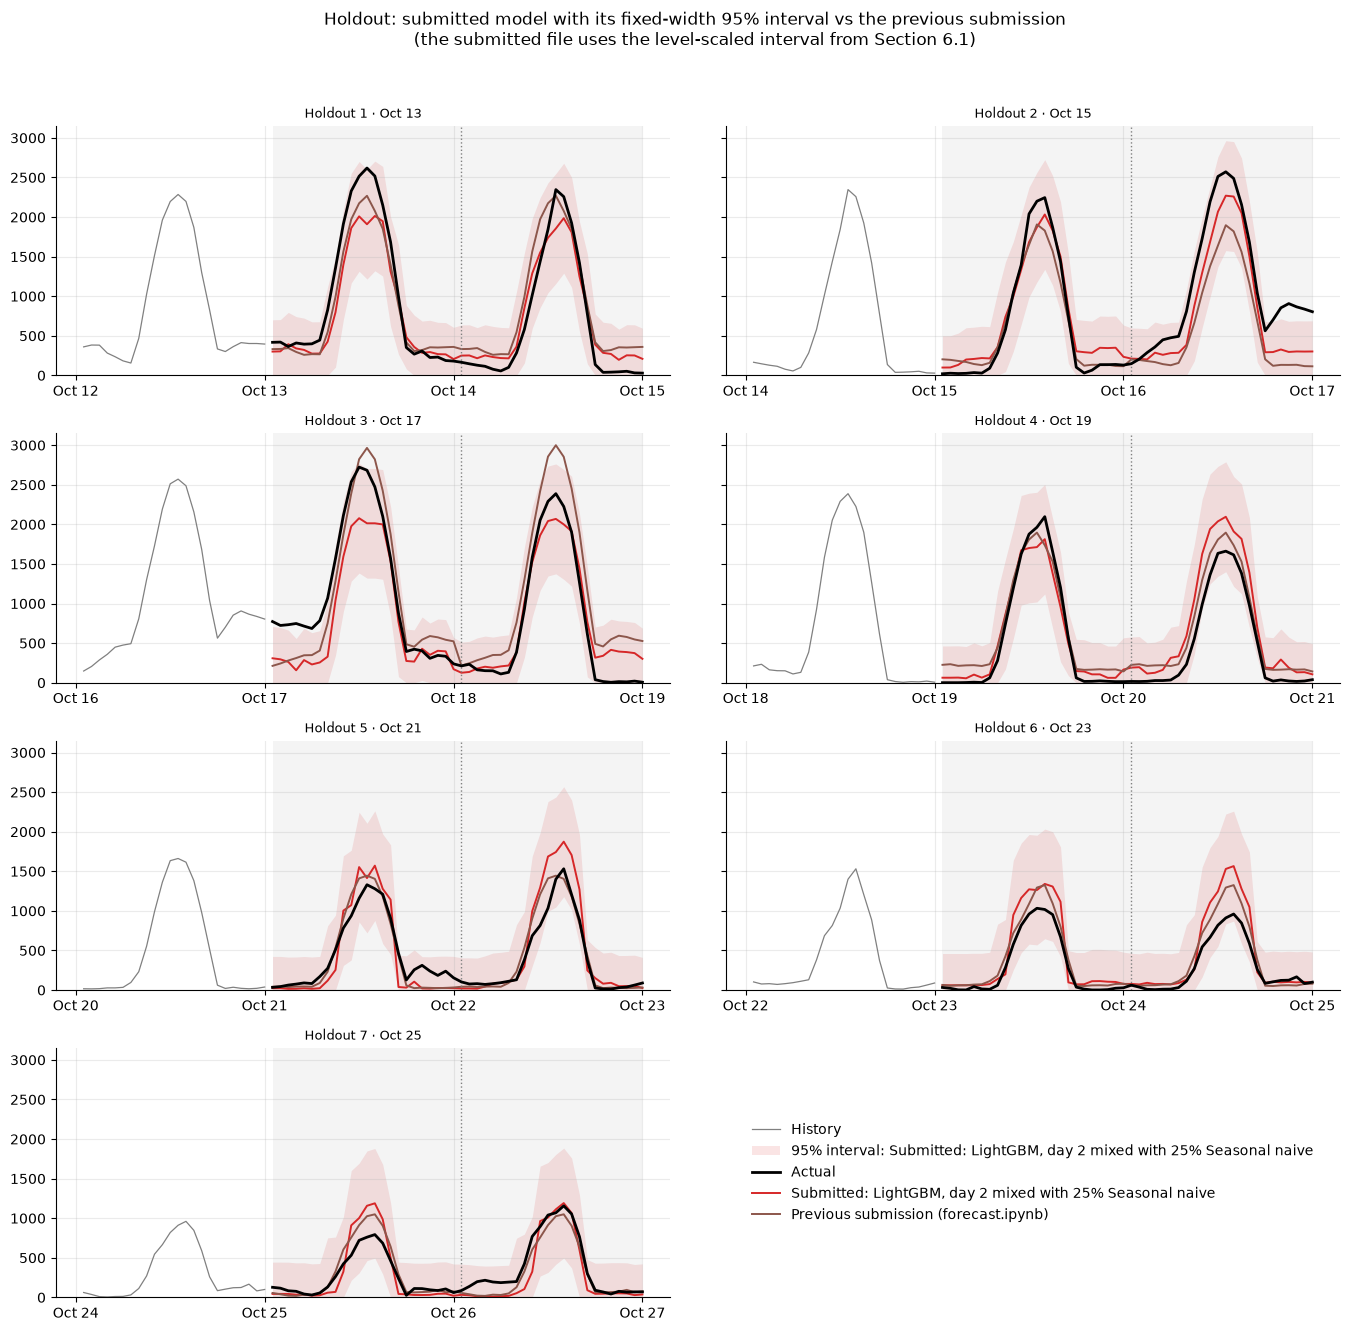

In [10]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharey=True)
plot_window_grid(
    fig, axes, data.ds, y, holdout_origins,
    {o: {k: candidates[k][o] for k in ['submitted', 'previous']} for o in holdout_origins},
    [f'Holdout {i} · {data.ds.iloc[o]:%b %d}' for i, o in enumerate(holdout_origins, start=1)],
    bands={o: ('submitted', *bands['submitted'][o]) for o in holdout_origins},
)
fig.suptitle('Holdout: submitted model with its fixed-width 95% interval vs the previous submission\n'
             '(the submitted file uses the level-scaled interval from Section 6.1)', y=1.02)
plt.tight_layout()
plt.show()

### 6.1 Interval width has to follow the level

The half-widths above are fixed numbers in units of `y`, set on CV windows where generation averaged about 820. By the end of the history the level is far lower (last 7 days: about 360), and errors shrink with it. A fixed width then becomes far too wide: on the public leaderboard (first 24 hidden hours) the previous submission scored Winkler 410 with a mean width of 365, while fixed widths from this notebook would give a width above 700.

**Level-scaled intervals** keep the same day/night and forecast-day split, but divide each CV error by the mean of `y` over the 7 days before its origin. The 95th percentile of these relative errors is multiplied by the recent level at forecast time.

The CV windows cannot judge this choice, because their level barely changes. The holdout can: its level falls from about 860 to 450. **This choice is therefore made on the holdout**, which the protocol otherwise keeps untouched. That is a deliberate exception, made because the forecast origin sits at a level that no CV window covers.

CV (14 windows)                   Holdout (7 windows)  \
                              Winkler coverage    width             Winkler   
Fixed width                   1094.12     0.95   989.15             1030.04   
Level-scaled (7 days)         1203.18     0.95  1034.47             1009.11   

                                        
                      coverage   width  
Fixed width               0.95  852.60  
Level-scaled (7 days)     0.92  779.02

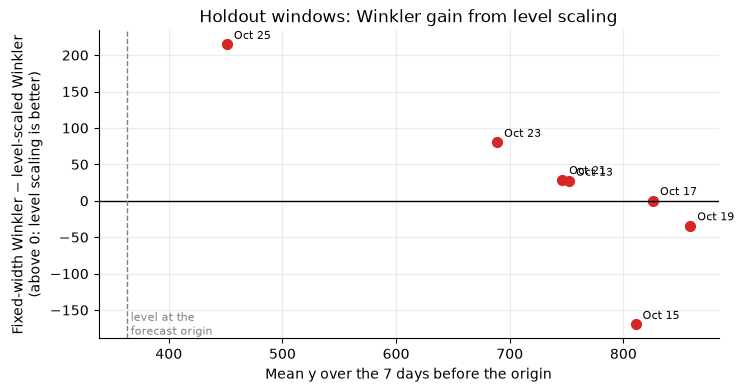

In [11]:
interval_schemes = {'Fixed width': None, 'Level-scaled (7 days)': INTERVAL_LEVEL_DAYS}
scheme_bands = {name: calibrated_bands(submitted, level_days=days) for name, days in interval_schemes.items()}
display(pd.concat({
    stage: pd.concat({name: pooled(origins, submitted, b).loc['1–48', ['Winkler', 'coverage', 'width']]
                      for name, b in scheme_bands.items()}, axis=1).T
    for stage, origins in [('CV (14 windows)', cv_origins), ('Holdout (7 windows)', holdout_origins)]
}, axis=1).round(2))

per_window = pd.DataFrame([
    {'origin': data.ds.iloc[o], 'level': recent_level(y, o, INTERVAL_LEVEL_DAYS),
     **{name: pooled([o], submitted, b).loc['1–48', 'Winkler'] for name, b in scheme_bands.items()}}
    for o in holdout_origins
])
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(per_window.level, per_window['Fixed width'] - per_window['Level-scaled (7 days)'], color=MODEL_COLORS['submitted'], s=50)
for _, row in per_window.iterrows():
    ax.annotate(f"{row.origin:%b %d}", (row.level, row['Fixed width'] - row['Level-scaled (7 days)']),
                textcoords='offset points', xytext=(5, 4), fontsize=8)
ax.axhline(0, color='black', lw=1)
ax.axvline(recent_level(y, N, INTERVAL_LEVEL_DAYS), color='grey', ls='--', lw=1)
ax.text(recent_level(y, N, INTERVAL_LEVEL_DAYS), ax.get_ylim()[0], ' level at the\n forecast origin', fontsize=8, va='bottom', color='grey')
ax.set(title='Holdout windows: Winkler gain from level scaling', xlabel='Mean y over the 7 days before the origin',
       ylabel='Fixed-width Winkler − level-scaled Winkler\n(above 0: level scaling is better)')
plt.show()

**Reading.** Over the whole holdout the two schemes are close, and on CV the fixed width is better. Per window the picture is clear: the lower the level, the more level scaling helps, and the last holdout window (the lowest level) gains the most. The forecast origin sits below every holdout window, so the submitted forecast uses **level-scaled intervals**.

## 7. Forecast for the next 48 hours

Refit on all history up to the forecast origin, with the supplied weather forecast. Intervals are level-scaled (Section 6.1). This is the submitted forecast: the cell writes `output/BARANIUK_project.csv` (the format checks are the same as in `forecast.ipynb`) and the overview plot used in the README. The earlier submission from `forecast.ipynb` is kept as `output/BARANIUK_project_ets_snaive_day3.csv`.

Mean interval width: hours 1–24 385, hours 25–48 366


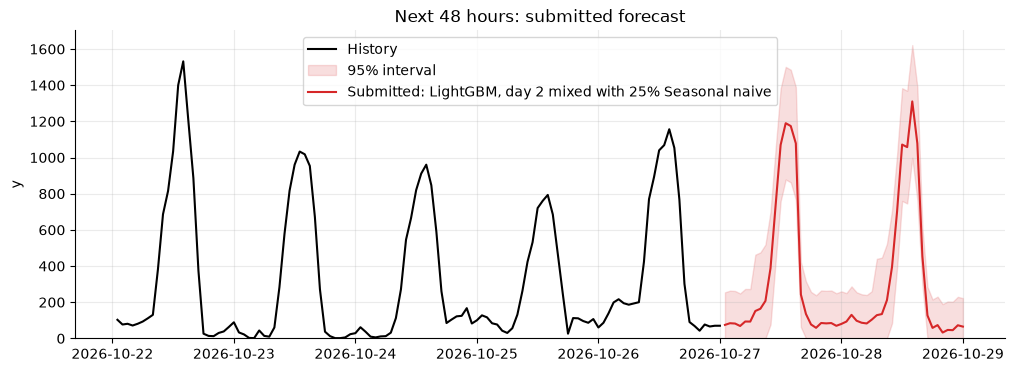

In [12]:
train = supervised[supervised.origin.between(N - TRAIN_WINDOW_DAYS * DAY, N - H)]
model = lgb.LGBMRegressor(**LGBM_PARAMS).fit(train[FEATURES], np.log(train.target) if LOG_TARGET else train.target)
lgbm_future = model.predict(make_features(y, N, future_weather)[FEATURES])
lgbm_future = np.exp(lgbm_future) if LOG_TARGET else np.maximum(lgbm_future, 0.1)
future_partners = {'autoets': autoets(data, N, ETS_TRAIN_DAYS), 'naive': seasonal_naive(y, N)}
(key1, w1), (key2, w2) = chosen_blend['1–24'], chosen_blend['25–48']
weights = np.repeat([w1, w2], DAY)
partner = np.concatenate([future_partners[key1][:DAY], future_partners[key2][DAY:]])
point = weights * lgbm_future + (1 - weights) * partner
lower, upper = interval(point, future_weather.daylight.to_numpy(dtype=int),
                        calibrate_halfwidths(y, daylight, cv_origins, submitted, level_days=INTERVAL_LEVEL_DAYS),
                        recent_level(y, N, INTERVAL_LEVEL_DAYS))
print(f'Mean interval width: hours 1–24 {np.mean((upper - lower)[:DAY]):.0f}, hours 25–48 {np.mean((upper - lower)[DAY:]):.0f}')

forecast = pd.DataFrame({'ds': future_weather.ds, 'forecast': point, 'lower_95': lower, 'upper_95': upper})
assert len(forecast) == H and forecast.notna().all().all()
assert (forecast.lower_95 >= 0).all()
assert ((forecast.lower_95 <= forecast.forecast) & (forecast.forecast <= forecast.upper_95)).all()
forecast.to_csv(ROOT / 'output/BARANIUK_project.csv', index=False)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(data.ds.iloc[-5 * DAY:], y[-5 * DAY:], color='black', label='History')
ax.fill_between(forecast.ds, lower, upper, color=MODEL_COLORS['submitted'], alpha=0.15, label='95% interval')
ax.plot(forecast.ds, point, color=MODEL_COLORS['submitted'], label=SUBMITTED_NAME)
ax.set(title='Next 48 hours: submitted forecast', ylabel='y')
ax.set_ylim(bottom=0)
ax.legend()
fig.savefig(ROOT / 'assets/forecast-overview.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Summary

| Decision | Options tried on CV | Chosen |
|---|---|---|
| Features | all; minus Wind, Other weather, both, both + calendar | all 19 features |
| Target | `y`, `log(y)` | `log(y)` |
| Blend partner | AutoETS, seasonal naive, per forecast day | none on day 1, seasonal naive on day 2 |
| Blend weight on LightGBM | 0, 0.25, 0.5, 0.75, 1 per forecast day | 1 on day 1, 0.75 on day 2 |
| Interval | fixed width or level-scaled, day/night, per forecast day, from CV errors | level-scaled (chosen on the holdout, Section 6.1) |

**Caveats**
- Historical scores give LightGBM the *observed* weather, so its holdout numbers are optimistic. The baseline notebook's noise test suggests the loss from forecast weather is small, but it is not zero.
- MAPE depends mostly on how many calm nights the hidden 48 hours contain. A ranking by MAPE on 7 holdout windows rests on 34 hours.
- The day-2 blend was chosen on CV by a margin smaller than the window-to-window spread, and the holdout preferred LightGBM alone. It is kept because the protocol fixes every choice on CV before the holdout is seen.
- The interval half-widths come from 14 × 48 CV errors. Level scaling assumes errors shrink in proportion to the level; at the forecast origin the level is below every CV and holdout window, so this is an extrapolation.
- `output/BARANIUK_project.csv` is now written by this notebook (Section 7). `forecast.ipynb` writes its own forecast to `output/BARANIUK_project_ets_snaive_day3.csv`.

**Conclusions** TODO: write 3–5 conclusions from the tables and plots above.